# Análise isolada dos códigos SCP-ECG da PTB-XL

**Notebook independente:** não treina Random Forest, não lê arquivos QRS e não modifica outros notebooks. Analisa os códigos individuais associados a **MI, STTC, CD, HYP, FORM e RHYTHM**, com inventário, frequências e coocorrências. Os códigos representam anotações eletrocardiográficas e não necessariamente doenças distintas.

**Entradas:** `ptbxl_database.csv` e `scp_statements.csv`. Ajuste `PASTA_PTBXL` abaixo. A análise usa os registros da base inteira; exclusões de registros conflitantes são calculadas separadamente e explicitamente, sem apagar os dados originais.

In [1]:
from pathlib import Path
from ast import literal_eval
from itertools import combinations
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# ALTERE PARA O DIRETÓRIO QUE CONTÉM OS CSVs DA PTB-XL
PASTA_PTBXL = Path('PTB-XL')
SAIDA = Path('Analise_Isolada_Codigos_SCP')
SAIDA.mkdir(parents=True, exist_ok=True)
CATEGORIAS = ['MI', 'STTC', 'CD', 'HYP', 'FORM', 'RHYTHM']

def encontrar(nome):
    candidatos = [PASTA_PTBXL / nome, Path(nome)]
    candidatos += list(PASTA_PTBXL.rglob(nome)) if PASTA_PTBXL.exists() else []
    for p in candidatos:
        if p.is_file(): return p
    raise FileNotFoundError(f'Não encontrei {nome}. Ajuste PASTA_PTBXL: {PASTA_PTBXL.resolve()}')

base = pd.read_csv(encontrar('ptbxl_database.csv'), usecols=['ecg_id', 'scp_codes'])
scp = pd.read_csv(encontrar('scp_statements.csv'), index_col=0)
scp.index = scp.index.astype(str).str.strip()
assert base.ecg_id.is_unique, 'ecg_id duplicado na tabela original'
print('ECGs originais:', len(base), '| códigos no dicionário:', len(scp))

ECGs originais: 21799 | códigos no dicionário: 71


In [2]:
def ativo(v):
    if pd.isna(v): return False
    if isinstance(v, str): return v.strip().lower() in ('1', '1.0', 'true', 'sim')
    return bool(v)

def categorias_do_codigo(codigo):
    if codigo not in scp.index: return []
    r = scp.loc[codigo]
    if isinstance(r, pd.DataFrame): r = r.iloc[0]
    categorias = []
    diagnostico = str(r.get('diagnostic_class', '')).strip().upper()
    if diagnostico in CATEGORIAS[:4]: categorias.append(diagnostico)
    if ativo(r.get('form', 0)): categorias.append('FORM')
    if ativo(r.get('rhythm', 0)): categorias.append('RHYTHM')
    return categorias

def ler_codigos(v):
    if pd.isna(v): return []
    try: obj = literal_eval(v) if isinstance(v, str) else v
    except (SyntaxError, ValueError): return []
    return sorted({str(c).strip() for c in obj}) if isinstance(obj, dict) else []

base['codigos'] = base.scp_codes.map(ler_codigos)
# Critério explícito e independente: NORM simultâneo a um código das quatro
# superclasses diagnósticas anormais. Não se pressupõe que o total seja 445.
conflitantes = set()
for ecg_id, codigos in base[['ecg_id','codigos']].itertuples(index=False, name=None):
    if 'NORM' in codigos and any(set(categorias_do_codigo(c)) & set(CATEGORIAS[:4]) for c in codigos):
        conflitantes.add(int(ecg_id))
pd.DataFrame({'ecg_id': sorted(conflitantes)}).to_csv(SAIDA/'ecgs_NORM_e_diagnostico_anormal.csv', index=False, encoding='utf-8-sig')
print('Conflitantes pelo critério NORM + MI/STTC/CD/HYP:',len(conflitantes))
print('ATENÇÃO: compare com sua lista original de 445 IDs antes de usar estas exclusões em experimentos.')

Conflitantes pelo critério NORM + MI/STTC/CD/HYP: 445
ATENÇÃO: compare com sua lista original de 445 IDs antes de usar estas exclusões em experimentos.


In [3]:
inventario=[]
for codigo in scp.index.unique():
    r=scp.loc[codigo]
    if isinstance(r,pd.DataFrame): r=r.iloc[0]
    for categoria in categorias_do_codigo(codigo):
        inventario.append({'categoria':categoria,'codigo_scp':codigo,
            'descricao':str(r.get('description','')),
            'subclasse_diagnostica':str(r.get('diagnostic_subclass',''))})
inventario=pd.DataFrame(inventario,columns=['categoria','codigo_scp','descricao','subclasse_diagnostica']).drop_duplicates()
inventario.to_csv(SAIDA/'inventario_codigos_por_categoria.csv',index=False,encoding='utf-8-sig')
print('Quantidade de códigos SCP no dicionário por categoria:')
display(inventario.groupby('categoria').codigo_scp.nunique().reindex(CATEGORIAS,fill_value=0).rename('n_codigos').to_frame())
display(inventario.sort_values(['categoria','codigo_scp']))

Quantidade de códigos SCP no dicionário por categoria:


,n_codigos
categoria,
MI,14
STTC,13
CD,11
HYP,5
FORM,19
RHYTHM,12


,categoria,codigo_scp,descricao,subclasse_diagnostica
14,CD,1AVB,first degree AV block,_AVB
46,CD,2AVB,second degree AV block,_AVB
44,CD,3AVB,third degree AV block,_AVB
18,CD,CLBBB,complete left bundle branch block,CLBBB
17,CD,CRBBB,complete right bundle branch block,CRBBB
...,...,...,...,...
30,STTC,ISCLA,ischemic in lateral leads,ISCA
12,STTC,ISC_,non-specific ischemic,ISC_
6,STTC,LNGQT,long QT-interval,STTC
0,STTC,NDT,non-diagnostic T abnormalities,STTC


In [4]:
linhas=[]
nao_mapeados=Counter()
for ecg_id,codigos in base[['ecg_id','codigos']].itertuples(index=False,name=None):
    for codigo in codigos:
        cats=categorias_do_codigo(codigo)
        if not cats: nao_mapeados[codigo]+=1
        for categoria in cats:
            linhas.append({'ecg_id':int(ecg_id),'categoria':categoria,'codigo_scp':codigo,
                           'excluido_conflito':int(ecg_id) in conflitantes})
long=pd.DataFrame(linhas,columns=['ecg_id','categoria','codigo_scp','excluido_conflito']).drop_duplicates()
long.to_csv(SAIDA/'ecgs_codigos_categorias.csv',index=False,encoding='utf-8-sig')
frequencia=(long.groupby(['categoria','codigo_scp'])
  .agg(n_ecgs_total=('ecg_id','nunique'),n_ecgs_conflitantes=('excluido_conflito','sum'))
  .reset_index())
frequencia['n_ecgs_sem_conflitantes']=frequencia.n_ecgs_total-frequencia.n_ecgs_conflitantes
frequencia=frequencia.merge(inventario,on=['categoria','codigo_scp'],how='left')
frequencia['categoria']=pd.Categorical(frequencia.categoria,categories=CATEGORIAS,ordered=True)
frequencia=frequencia.sort_values(['categoria','n_ecgs_total'],ascending=[True,False])
frequencia.to_csv(SAIDA/'frequencia_codigos_por_categoria.csv',index=False,encoding='utf-8-sig')
resumo=(long.groupby('categoria').agg(n_ecgs_total=('ecg_id','nunique'),
    n_codigos_observados=('codigo_scp','nunique')).reindex(CATEGORIAS,fill_value=0).reset_index())
resumo['n_codigos_dicionario']=resumo.categoria.map(inventario.groupby('categoria').codigo_scp.nunique()).fillna(0).astype(int)
resumo.to_csv(SAIDA/'resumo_seis_categorias.csv',index=False,encoding='utf-8-sig')
display(resumo)
display(frequencia)

,categoria,n_ecgs_total,n_codigos_observados,n_codigos_dicionario
0,MI,5469,14,14
1,STTC,5235,13,13
2,CD,4898,11,11
3,HYP,2649,5,5
4,FORM,8978,19,19
5,RHYTHM,21030,12,12


,categoria,codigo_scp,n_ecgs_total,n_ecgs_conflitantes,n_ecgs_sem_conflitantes,descricao,subclasse_diagnostica
39,MI,IMI,2676,1,2675,inferior myocardial infarction,IMI
37,MI,ASMI,2357,0,2357,anteroseptal myocardial infarction,AMI
38,MI,ILMI,478,0,478,inferolateral myocardial infarction,IMI
36,MI,AMI,353,0,353,anterior myocardial infarction,AMI
35,MI,ALMI,288,0,288,anterolateral myocardial infarction,AMI
...,...,...,...,...,...,...,...
51,RHYTHM,BIGU,82,0,82,"bigeminal pattern (unknown origin, SV or Ventr...",nan
50,RHYTHM,AFLT,73,0,73,atrial flutter,nan
59,RHYTHM,SVTAC,27,0,27,supraventricular tachycardia,nan
53,RHYTHM,PSVT,24,0,24,paroxysmal supraventricular tachycardia,nan


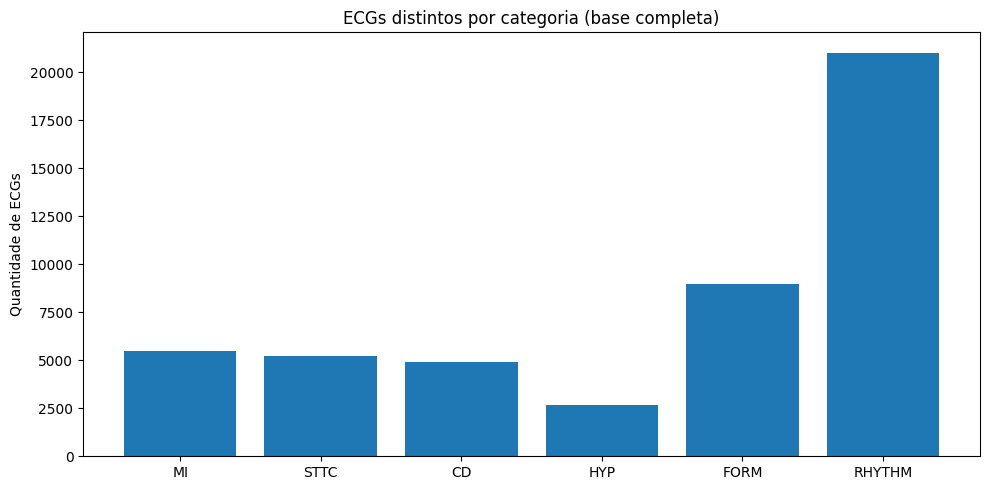

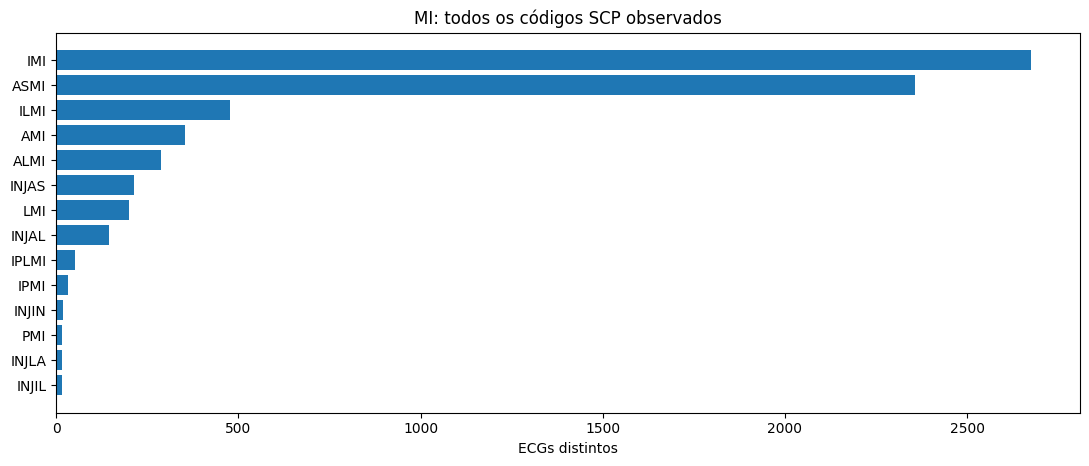

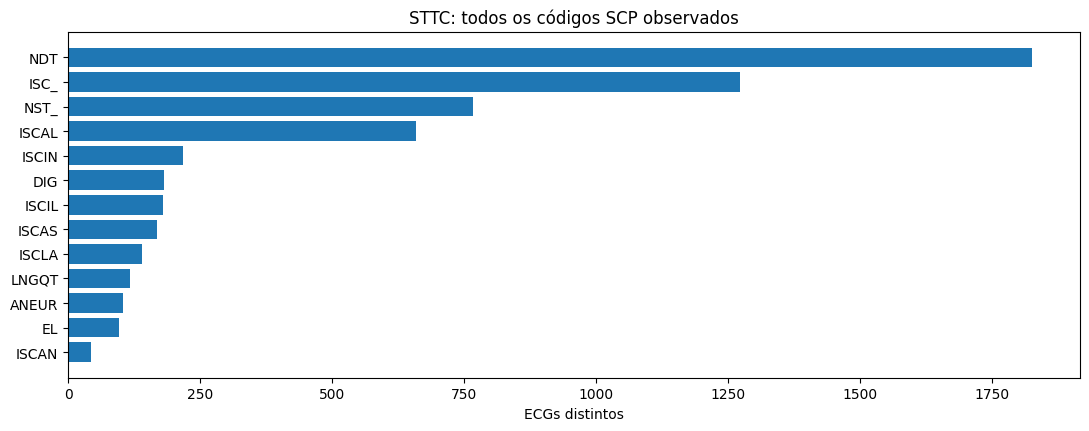

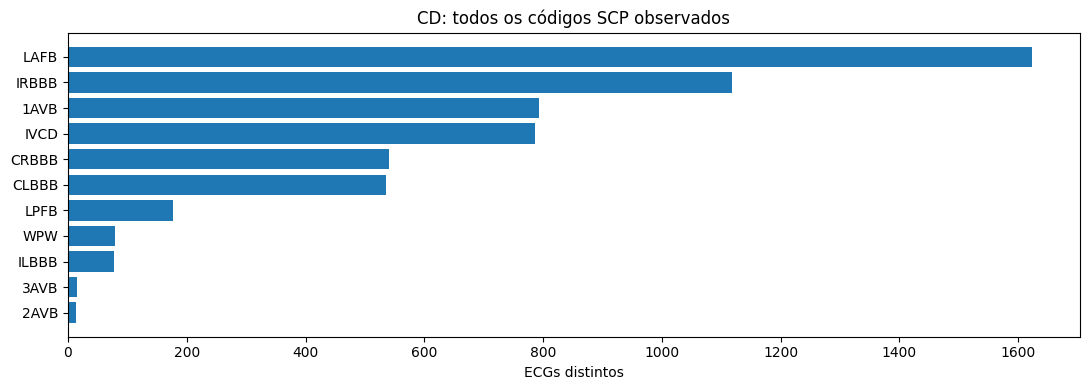

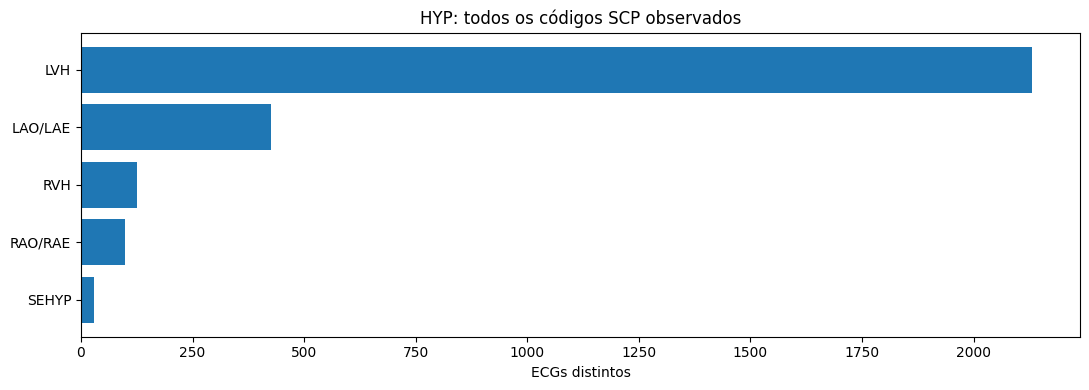

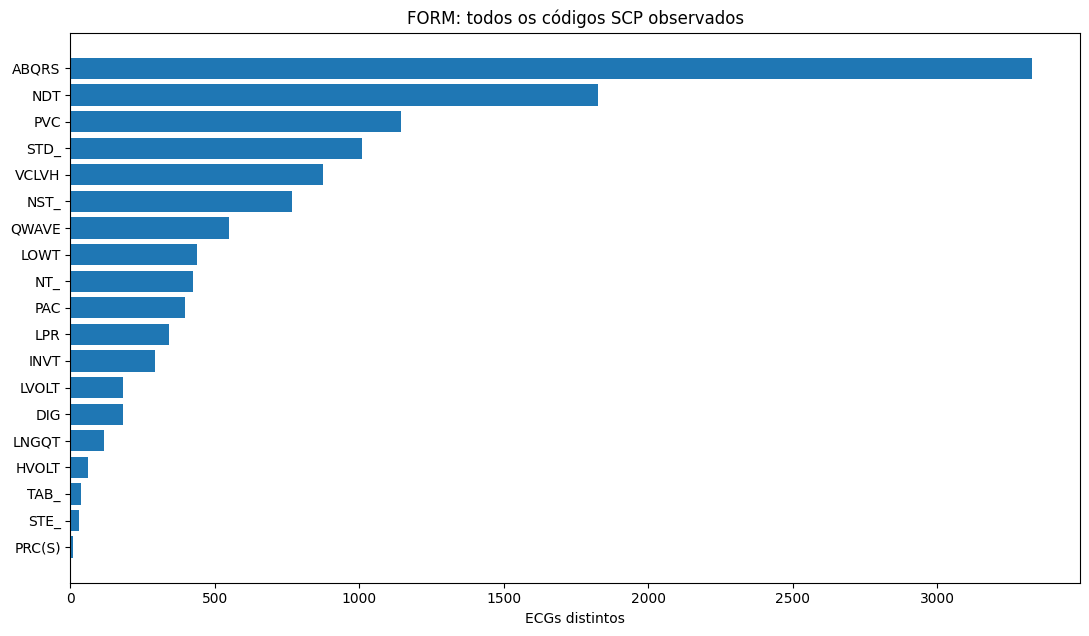

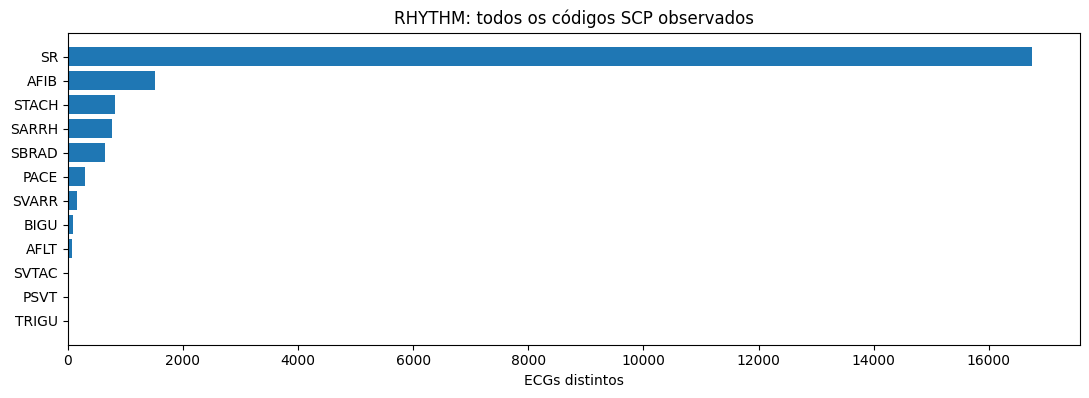

In [5]:
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(resumo.categoria,resumo.n_ecgs_total)
ax.set(title='ECGs distintos por categoria (base completa)',ylabel='Quantidade de ECGs')
fig.tight_layout();fig.savefig(SAIDA/'ecgs_por_categoria.png',dpi=180);plt.show()
for cat in CATEGORIAS:
    dados=frequencia[frequencia.categoria.eq(cat)].sort_values('n_ecgs_total')
    if dados.empty: continue
    fig,ax=plt.subplots(figsize=(11,max(4,len(dados)*0.34)))
    ax.barh(dados.codigo_scp.astype(str),dados.n_ecgs_total)
    ax.set(title=f'{cat}: todos os códigos SCP observados',xlabel='ECGs distintos')
    fig.tight_layout();fig.savefig(SAIDA/f'codigos_{cat}.png',dpi=180,bbox_inches='tight');plt.show()

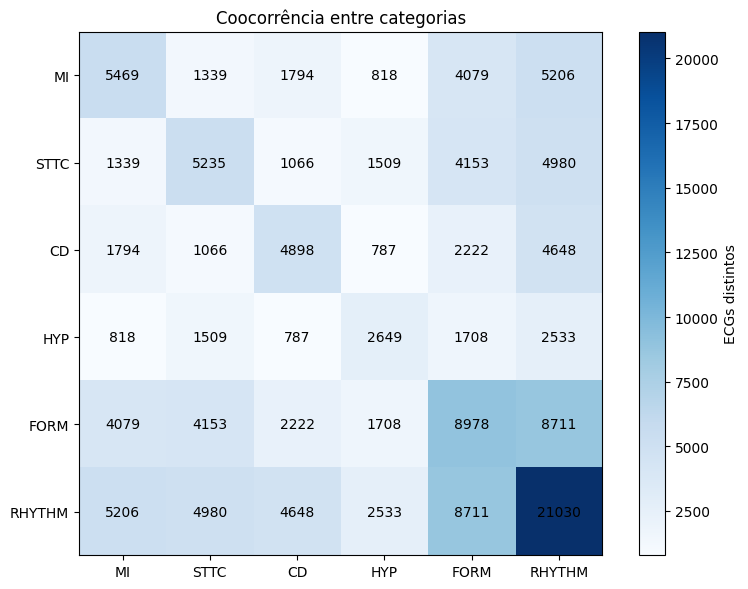

,MI,STTC,CD,HYP,FORM,RHYTHM
MI,5469,1339,1794,818,4079,5206
STTC,1339,5235,1066,1509,4153,4980
CD,1794,1066,4898,787,2222,4648
HYP,818,1509,787,2649,1708,2533
FORM,4079,4153,2222,1708,8978,8711
RHYTHM,5206,4980,4648,2533,8711,21030


,codigo_a,codigo_b,n_ecgs
2,ABQRS,SR,2534
3,IMI,SR,1980
33,ASMI,SR,1574
11,LVH,SR,1518
1,ABQRS,IMI,1477
7,NDT,SR,1381
22,LAFB,SR,1233
60,ISC_,LVH,1169
32,ABQRS,ASMI,1160
25,IRBBB,SR,832


In [6]:
por_ecg=long.groupby('ecg_id').categoria.agg(lambda x:set(x))
matriz=pd.DataFrame(0,index=CATEGORIAS,columns=CATEGORIAS,dtype=int)
for categorias in por_ecg:
    for a in categorias:
        for b in categorias: matriz.loc[a,b]+=1
matriz.to_csv(SAIDA/'coocorrencia_categorias.csv',encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(matriz.to_numpy(),cmap='Blues')
ax.set_xticks(range(6),CATEGORIAS);ax.set_yticks(range(6),CATEGORIAS)
for i in range(6):
    for j in range(6):ax.text(j,i,str(matriz.iat[i,j]),ha='center',va='center')
fig.colorbar(im,ax=ax,label='ECGs distintos');ax.set_title('Coocorrência entre categorias')
fig.tight_layout();fig.savefig(SAIDA/'coocorrencia_categorias.png',dpi=180);plt.show()
pares=Counter()
for codigos in long.groupby('ecg_id').codigo_scp.unique():
    pares.update(combinations(sorted(set(codigos)),2))
pares_df=pd.DataFrame([{'codigo_a':a,'codigo_b':b,'n_ecgs':q} for (a,b),q in pares.items()],columns=['codigo_a','codigo_b','n_ecgs'])
if not pares_df.empty:pares_df=pares_df.sort_values('n_ecgs',ascending=False)
pares_df.to_csv(SAIDA/'coocorrencia_pares_codigos.csv',index=False,encoding='utf-8-sig')
display(matriz);display(pares_df.head(30))

## Interpretação

- O **inventário** conta códigos definidos no dicionário, inclusive os que não aparecem em registros.
- A **frequência** conta ECGs distintos, não batimentos nem doenças únicas.
- Categorias e códigos podem coexistir; por isso, somas por categoria podem ultrapassar o número de ECGs.
- `FORM` e `RHYTHM` são sinalizados por colunas próprias no dicionário e não são superclasses diagnósticas do mesmo tipo de `MI`, `STTC`, `CD` e `HYP`.
- A lista de exclusão calculada aqui é **exploratória**; confirme-a contra os 445 IDs do seu pipeline antes de aplicar exclusões definitivas.

In [7]:
print('Arquivos exportados em:',SAIDA.resolve())
for p in sorted(SAIDA.iterdir()):print(' -',p.name)

Arquivos exportados em: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Analise_Isolada_Codigos_SCP
 - codigos_CD.png
 - codigos_FORM.png
 - codigos_HYP.png
 - codigos_MI.png
 - codigos_RHYTHM.png
 - codigos_STTC.png
 - coocorrencia_categorias.csv
 - coocorrencia_categorias.png
 - coocorrencia_pares_codigos.csv
 - ecgs_codigos_categorias.csv
 - ecgs_NORM_e_diagnostico_anormal.csv
 - ecgs_por_categoria.png
 - frequencia_codigos_por_categoria.csv
 - inventario_codigos_por_categoria.csv
 - resumo_seis_categorias.csv


## Classe 0 — Normal / Sinusal

Esta seção complementa as seis categorias existentes, **sem modificar suas análises**. A regra adotada para a classe 0 considera os códigos `NORM`, `SR`, `SBRAD`, `STACH` e `SARRH`, conforme a definição do projeto. Registros com `NORM` e diagnósticos anormais MI/STTC/CD/HYP são excluídos da classe 0, usando o conjunto exploratório `conflitantes` já calculado.

**Atenção:** os códigos de ritmo sinusal não garantem ausência de outras alterações. Por isso, os resultados apresentam separadamente os casos com diagnósticos anormais concomitantes, para auditoria.


In [10]:
# Composição da classe 0: códigos e registros elegíveis
CODIGOS_ZERO = ['NORM', 'SR']
CATS_DIAGNOSTICAS_ANORMAIS = {'MI', 'STTC', 'CD', 'HYP'}

def codigos_anormais_do_ecg(codigos):
    return sorted(c for c in codigos if set(categorias_do_codigo(c)) & CATS_DIAGNOSTICAS_ANORMAIS)

linhas_zero = []
for ecg_id, codigos in base[['ecg_id', 'codigos']].itertuples(index=False, name=None):
    presentes = sorted(set(codigos) & set(CODIGOS_ZERO))
    if not presentes:
        continue
    anormais = codigos_anormais_do_ecg(codigos)
    linhas_zero.append({
        'ecg_id': int(ecg_id),
        'codigos_classe_0': ', '.join(presentes),
        'n_codigos_classe_0': len(presentes),
        'tem_NORM': 'NORM' in presentes,
        'tem_ritmo_sinusal': bool(set(presentes) & (set(CODIGOS_ZERO)-{'NORM'})),
        'codigos_diagnosticos_anormais': ', '.join(anormais),
        'tem_diagnostico_anormal': bool(anormais),
        'excluido_NORM_mais_anormal': int(ecg_id) in conflitantes,
        'elegivel_classe_0_regra_original': int(ecg_id) not in conflitantes,
        'elegivel_classe_0_criterio_estrito': int(ecg_id) not in conflitantes and not anormais,
    })

colunas_zero = ['ecg_id','codigos_classe_0','n_codigos_classe_0','tem_NORM',
                'tem_ritmo_sinusal','codigos_diagnosticos_anormais','tem_diagnostico_anormal',
                'excluido_NORM_mais_anormal','elegivel_classe_0_regra_original',
                'elegivel_classe_0_criterio_estrito']
df_zero = pd.DataFrame(linhas_zero, columns=colunas_zero)
df_zero.to_csv(SAIDA/'classe_0_registros_composicao.csv', index=False, encoding='utf-8-sig')

print('ECGs com ao menos um código candidato à classe 0:', len(df_zero))
print('Excluídos por NORM + MI/STTC/CD/HYP:', int(df_zero.excluido_NORM_mais_anormal.sum()))
print('Elegíveis pela regra original:', int(df_zero.elegivel_classe_0_regra_original.sum()))
print('Elegíveis pelo critério estrito (sem qualquer MI/STTC/CD/HYP):',
      int(df_zero.elegivel_classe_0_criterio_estrito.sum()))
print('ATENÇÃO: compare as duas regras antes de usar a classe 0 em treinamento.')
display(df_zero.head(20))


ECGs com ao menos um código candidato à classe 0: 18058
Excluídos por NORM + MI/STTC/CD/HYP: 445
Elegíveis pela regra original: 17613
Elegíveis pelo critério estrito (sem qualquer MI/STTC/CD/HYP): 9083
ATENÇÃO: compare as duas regras antes de usar a classe 0 em treinamento.


,ecg_id,codigos_classe_0,n_codigos_classe_0,tem_NORM,tem_ritmo_sinusal,codigos_diagnosticos_anormais,tem_diagnostico_anormal,excluido_NORM_mais_anormal,elegivel_classe_0_regra_original,elegivel_classe_0_criterio_estrito
0,1,"NORM, SR",2,True,True,,False,False,True,True
1,2,NORM,1,True,False,,False,False,True,True
2,3,"NORM, SR",2,True,True,,False,False,True,True
3,4,"NORM, SR",2,True,True,,False,False,True,True
4,5,"NORM, SR",2,True,True,,False,False,True,True
5,6,"NORM, SR",2,True,True,,False,False,True,True
6,7,"NORM, SR",2,True,True,,False,False,True,True
7,8,SR,1,False,True,IMI,True,False,True,False
8,9,"NORM, SR",2,True,True,,False,False,True,True
9,10,"NORM, SR",2,True,True,,False,False,True,True


,rotulo,codigo_scp,descricao_ptbxl,n_ecgs_base_completa,n_ecgs_excluidos_conflito,n_ecgs_classe_0_regra_original,n_ecgs_classe_0_criterio_estrito
0,0,NORM,normal ECG,9514,445,9069,9069
1,0,SR,sinus rhythm,16748,359,16389,7859


,NORM,SR
NORM,9069,7845
SR,7845,16389


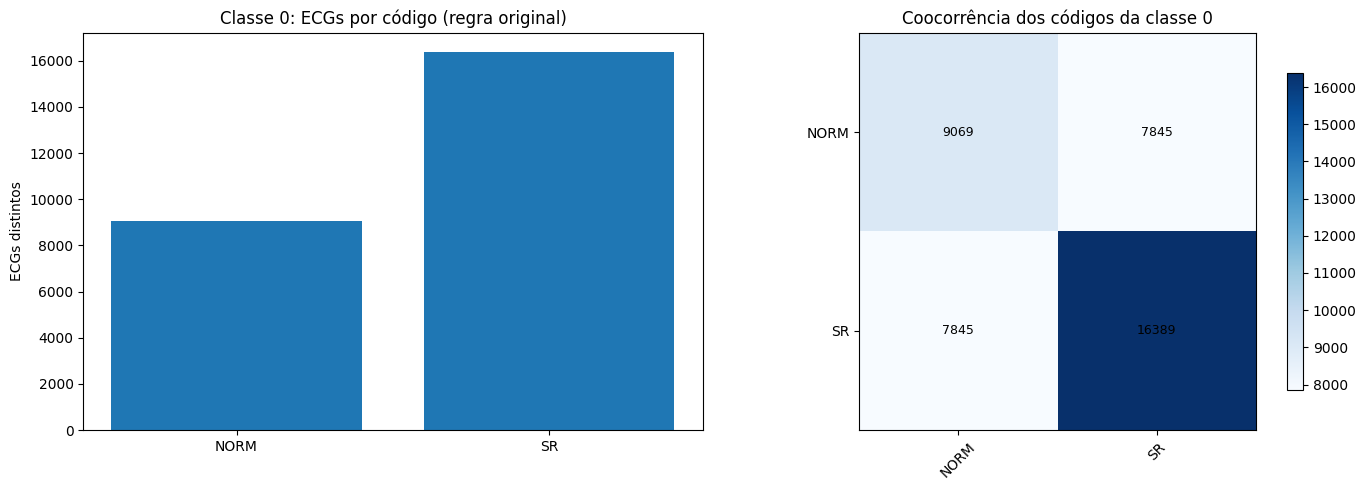

In [11]:
# Frequência de cada código da classe 0 e coocorrências
linhas_codigos_zero = []
for codigo in CODIGOS_ZERO:
    r = scp.loc[codigo] if codigo in scp.index else None
    if isinstance(r, pd.DataFrame): r = r.iloc[0]
    mascara = base.codigos.map(lambda cs: codigo in cs)
    ids = set(base.loc[mascara, 'ecg_id'].astype(int))
    ids_elegiveis = set(df_zero.loc[df_zero.elegivel_classe_0_regra_original, 'ecg_id'])
    ids_estritos = set(df_zero.loc[df_zero.elegivel_classe_0_criterio_estrito, 'ecg_id'])
    linhas_codigos_zero.append({
        'rotulo': '0', 'codigo_scp': codigo,
        'descricao_ptbxl': str(r.get('description', '')) if r is not None else 'Não encontrado em scp_statements.csv',
        'n_ecgs_base_completa': len(ids),
        'n_ecgs_excluidos_conflito': len(ids & conflitantes),
        'n_ecgs_classe_0_regra_original': len(ids & ids_elegiveis),
        'n_ecgs_classe_0_criterio_estrito': len(ids & ids_estritos),
    })
frequencia_zero = pd.DataFrame(linhas_codigos_zero)
frequencia_zero.to_csv(SAIDA/'classe_0_frequencia_codigos.csv', index=False, encoding='utf-8-sig')
display(frequencia_zero)

cooc_zero = pd.DataFrame(0, index=CODIGOS_ZERO, columns=CODIGOS_ZERO, dtype=int)
for codigos in df_zero.loc[df_zero.elegivel_classe_0_regra_original, 'codigos_classe_0']:
    presentes = [c.strip() for c in codigos.split(',') if c.strip()]
    for a in presentes:
        for b in presentes:
            cooc_zero.loc[a,b] += 1
cooc_zero.to_csv(SAIDA/'classe_0_coocorrencia_codigos.csv', encoding='utf-8-sig')
display(cooc_zero)

fig, axes = plt.subplots(1,2,figsize=(14,5))
axes[0].bar(frequencia_zero.codigo_scp, frequencia_zero.n_ecgs_classe_0_regra_original)
axes[0].set(title='Classe 0: ECGs por código (regra original)', ylabel='ECGs distintos')
im = axes[1].imshow(cooc_zero.values, cmap='Blues')
axes[1].set_xticks(range(len(CODIGOS_ZERO)), CODIGOS_ZERO, rotation=45)
axes[1].set_yticks(range(len(CODIGOS_ZERO)), CODIGOS_ZERO)
for i in range(len(CODIGOS_ZERO)):
    for j in range(len(CODIGOS_ZERO)):
        axes[1].text(j,i,str(cooc_zero.iat[i,j]),ha='center',va='center',fontsize=9)
axes[1].set_title('Coocorrência dos códigos da classe 0')
fig.colorbar(im, ax=axes[1], shrink=.8)
fig.tight_layout()
fig.savefig(SAIDA/'classe_0_composicao.png', dpi=180, bbox_inches='tight')
plt.show()


#### Confirmar se tem Bradicardia sr , taquicardia sr ou arritmia sr dentro instancias_NORM_e_anormal_juntos.csv

In [22]:

import pandas as pd
import ast
import re
from pathlib import Path
from IPython.display import display

# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

PASTA = Path.cwd()

PASTA_ECG = PASTA / "ECG_Organizados"
PASTA_QRS = PASTA / "Recortes-QRS"

CODIGOS_VERIFICAR = {
    "SBRAD": "Bradicardia sinusal",
    "STACH": "Taquicardia sinusal",
    "SARRH": "Arritmia sinusal"
}

# ============================================================
# 2. LOCALIZAR O CSV ORIGINAL DA PTB-XL
# ============================================================

arquivos_base = sorted(
    p for p in PASTA.rglob("ptbxl_database*.csv")
    if not any(
        parte.lower() in {
            "resultados",
            "recortes-qrs",
            "ecg_organizados"
        }
        for parte in p.relative_to(PASTA).parts
    )
)

if len(arquivos_base) != 1:
    raise RuntimeError(
        "Esperado exatamente um arquivo ptbxl_database*.csv. "
        f"Encontrados: {arquivos_base}"
    )

ARQUIVO = arquivos_base[0]

for pasta in [PASTA_ECG, PASTA_QRS]:
    if not pasta.is_dir():
        raise FileNotFoundError(
            f"Pasta não encontrada: {pasta}"
        )

# ============================================================
# 3. IDENTIFICAR TODOS OS ECGs COM OS TRÊS CÓDIGOS
# ============================================================

df = pd.read_csv(
    ARQUIVO,
    usecols=["ecg_id", "scp_codes"]
)

df["ecg_id"] = pd.to_numeric(
    df["ecg_id"],
    errors="raise"
).astype(int)

if df["ecg_id"].duplicated().any():
    raise ValueError("Existem ecg_id duplicados no CSV.")

def identificar_sinusais(valor):

    codigos = (
        ast.literal_eval(valor)
        if isinstance(valor, str)
        else valor
    )

    if not isinstance(codigos, dict):
        raise ValueError(
            f"scp_codes inválido: {valor}"
        )

    return sorted(
        set(codigos) & set(CODIGOS_VERIFICAR)
    )

df["sinusais_encontrados"] = (
    df["scp_codes"].apply(identificar_sinusais)
)

df_sinusais = df[
    df["sinusais_encontrados"].apply(bool)
].copy()

ids_sinusais = set(df_sinusais["ecg_id"])

# ============================================================
# 4. PERCORRER TODAS AS PASTAS E SUBPASTAS
# ============================================================

def localizar_ecgs(pasta_raiz, origem, ids_procurados):

    registros = []

    for hea in pasta_raiz.rglob("*.hea"):

        match = re.fullmatch(
            r"(\d+)(?:_(?:hr|lr))?",
            hea.stem,
            flags=re.IGNORECASE
        )

        if match is None:
            continue

        ecg_id = int(match.group(1))

        if ecg_id not in ids_procurados:
            continue

        registros.append({
            "ecg_id": ecg_id,
            "origem": origem,
            "pasta": str(hea.parent)
        })

    return registros

# ============================================================
# 5. PROCURAR EM ECG_Organizados E Recortes-QRS
# ============================================================

registros = []

registros.extend(
    localizar_ecgs(
        PASTA_ECG,
        "ECG_Organizados",
        ids_sinusais
    )
)

registros.extend(
    localizar_ecgs(
        PASTA_QRS,
        "Recortes-QRS",
        ids_sinusais
    )
)

# ============================================================
# 6. ORGANIZAR RESULTADOS
# ============================================================

df_resultado = pd.DataFrame(
    registros,
    columns=["ecg_id", "origem", "pasta"]
)

df_resultado = (
    df_resultado
    .drop_duplicates()
    .sort_values(["ecg_id", "origem", "pasta"])
    .reset_index(drop=True)
)

# ============================================================
# 7. EXIBIR SOMENTE ID E PASTA
# ============================================================

print("=" * 70)
print("LOCALIZAÇÃO DOS ECGs COM SBRAD, STACH OU SARRH")
print("=" * 70)

print(
    "Total de ECGs com os três códigos:",
    len(ids_sinusais)
)

print(
    "ECGs encontrados nas pastas:",
    df_resultado["ecg_id"].nunique()
)

print(
    "ECGs não encontrados:",
    len(ids_sinusais - set(df_resultado["ecg_id"]))
)

print("\nECG_Organizados:")

display(
    df_resultado.loc[
        df_resultado["origem"] == "ECG_Organizados",
        ["ecg_id", "pasta"]
    ].reset_index(drop=True)
)

print("\nRecortes-QRS:")

display(
    df_resultado.loc[
        df_resultado["origem"] == "Recortes-QRS",
        ["ecg_id", "pasta"]
    ].reset_index(drop=True)
)

# ============================================================
# 8. EXPORTAR RELATÓRIOS
# ============================================================

SAIDA_ECG = (
    PASTA / "localizacao_SRs_ECG_Organizados.csv"
)

SAIDA_QRS = (
    PASTA / "localizacao_SRs_Recortes_QRS.csv"
)

df_resultado.loc[
    df_resultado["origem"] == "ECG_Organizados",
    ["ecg_id", "pasta"]
].to_csv(
    SAIDA_ECG,
    index=False,
    encoding="utf-8-sig"
)

df_resultado.loc[
    df_resultado["origem"] == "Recortes-QRS",
    ["ecg_id", "pasta"]
].to_csv(
    SAIDA_QRS,
    index=False,
    encoding="utf-8-sig"
)

print("\nRELATÓRIOS EXPORTADOS:")
print(SAIDA_ECG)
print(SAIDA_QRS)

print("\nNenhum arquivo original foi modificado.")


FileNotFoundError: Pasta não encontrada: c:\Users\Matheus\Documents\Detctor-automatizado-QRS\ECG_Organizados

FileNotFoundError: Pasta ECG_Organizados não encontrada: c:\Users\Matheus\Documents\Detctor-automatizado-QRS\ECG_Organizados

### Interpretação da classe 0

- **Base completa:** todos os ECGs que contêm cada código.
- **Regra original:** ECGs com `NORM` e/ou códigos sinusais, removendo os conflitos `NORM` + diagnóstico anormal.
- **Critério estrito (comparativo):** também remove ECGs com código sinusal acompanhado de MI/STTC/CD/HYP, mesmo sem `NORM`.
- As frequências dos códigos **não devem ser somadas**, pois um ECG pode apresentar vários deles.
- A análise é descritiva e não altera a divisão de treinamento, validação e teste.
